In [1]:
experiement_pth = '../test_results/evals'
analysis_pth = '../test_results/plots/'

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

def compare_loss_curves(models, labels, losses=['total loss'], path="", yscales=['linear'], interval=10):

    ### Check if save directory exists
    os.makedirs(os.path.join(experiement_pth, path), exist_ok=True)

    
    # Plot each loss
    for i, loss in enumerate(losses):
        plt.close()
        plt.title(loss)
        for j, mdl in enumerate(models):
            df = pd.read_csv(os.path.join(mdl, 'losses.csv'))
            plt.plot(df[loss][::interval], label=labels[j])
        plt.yscale(yscales[i])
        plt.legend()
        plt.savefig(os.path.join(experiement_pth, path, loss + '.png'))
        plt.show()

def get_success_rate_and_steps(path):
    df = pd.read_csv(path)

    successes = df['evaluation/success'].to_list()
    successes = [n.strip("[]").split(", ") for n in successes]
    successes = [[1 if mm == 'True' else 0 for mm in n] for n in successes]
    # successes = np.asarray(successes)

    eps = len(successes)
    ## reduce the succeess to 1 if any of the episode is success
    success_eps = []
    for i in range(eps):
        success_eps.append(np.any(successes[i]))

    # get the success rate
    rate = np.sum(success_eps) / len(success_eps)

    ## get steps-to-success if an episode is success
    steps_to_success = []
    for i in range(eps):
        if success_eps[i]:
            steps_to_success.append(np.argmax(successes[i])+1)
        else:
            steps_to_success.append(30)
    
    # np.argmax(successes, axis=1)

    # filter out the episode that is not success
    # steps_to_success = np.asarray(steps_to_success)
    # steps_to_success = steps_to_success[success_eps]

    return rate, steps_to_success, eps

def get_metrics(path, step=30, success_criteria=0):
    df = pd.read_csv(path)

    if success_criteria == 0:
        success_fn = lambda x, y: x > 0.90 and y > 0.80
    elif success_criteria == 1:
        success_fn = lambda x, y: x > 0.90


    NC = df['evaluation/normalised_coverage'].to_list()
    NC = [n.strip("[]").split(", ") for n in NC]
    NC = [[float(mm) for mm in n] for n in NC]
    NC = np.asarray(NC)
    ret_NC = []
    NI = df['evaluation/normalised_improvement'].to_list()
    NI = [n.strip("[]").split(", ") for n in NI]
    NI = [[float(mm) for mm in n] for n in NI]
    ret_NI = []

    IoU = df['evaluation/max_IoU'].to_list()
    IoU = [n.strip("[]").split(", ") for n in IoU]
    IoU = [[float(mm) for mm in n] for n in IoU]
    ret_IoU = []

    HD = df['evaluation/normalised_hausdorff_distance'].to_list()
    HD = [n.strip("[]").split(", ") for n in HD]
    HD = [[float(mm) for mm in n] for n in HD]
    ret_HD = []
    step2success = []

    for i in range(len(NC)):
        ret_NC.append(NC[i][-1])
        ret_NI.append(NI[i][-1])
        ret_IoU.append(IoU[i][-1])
        ret_HD.append(HD[i][-1])
        step2success.append(len(NC[i])-1)
        for j in range(len(NC[i])):
            if success_fn(NC[i][j], IoU[i][j]):
                ret_NC[-1] = NC[i][j]
                ret_NI[-1] = NI[i][j]
                ret_IoU[-1] = IoU[i][j]
                ret_HD[-1] = HD[i][j]
                step2success[-1] = j
                break
    
    total_eps = len(NC)
    success_eps = 0
    # get SR, for each episode, NC should be larger than 0.99 and IoU should be larger than 0.85

    for i in range(total_eps):
        if success_fn(ret_NC[i], ret_IoU[i]):
            success_eps += 1



    return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success

In [3]:
agents = [
    'rssm',
    'gc_rssm',
]

objects = [
    'longsleeve',
    'smallLongsleeve',
    'pants',
    'smallPants',
    'skirt',
    'smallSkirt',
    'dress',
    'smallDress',
    'mono-square-fabric'
]

step=30
arenas = []
arena_label = []

### Collect all the config for each arena, agent
configs = {ag: []  for ag in agents}
for ag in agents:
    lafruita_path = os.path.join(experiement_pth, ag)
    if os.path.exists(lafruita_path):
        for cf in os.listdir(lafruita_path):
            path_to_check = os.path.join(lafruita_path, cf)
            configs[ag].append(cf)
data = {
    'task': [],
    'agent': [],
    'config': [],
    # 'domain': [],
    'object': [],
    # 'success rate': [],
    # 'steps to success': [],
    # 'steps to success std': [],
    'ni': [], # largest particle distance
    'nc': [],
    'ni std': [],
    'nc std': [],
    'IoU': [],
    'HD': [],
    'IoU std': [],
    'HD std': [],
    'steps': [],
    'steps std': [],
    # 'max key dist': [],
    # 'mean key dist': [],
    'episodes': [],
    'success_eps': [],
    'path': [],
    'checkpoint': []
}
print(arenas)
### For all configs, get the success rate and steps to success

for ag in agents:
    #print('\n', " "*4, 'Agent:', agent_lable[ar][agents[ar].index(ag)])
    for cf in configs[ag]:
        for ob in objects:
            path = os.path.join(experiement_pth, ag, cf, ob)
            if not os.path.isdir(path):
                continue

            for f in os.listdir(path):
                #print(f)
                if 'manupilation' not in f:
                    continue
            
                path_to_check = os.path.join(path, f, 'performance.csv') 
                
                #print(path_to_check)
                
                if os.path.exists(path_to_check):

                    checkpoint_parsing = f.split('.')[0].split('_')
                    #print(checkpoint_parsing)
                    if len(checkpoint_parsing) == 2:
                        if checkpoint_parsing[1] == '':
                            continue
                        #print(checkpoint_parsing[1])
                        data['checkpoint'].append(str(checkpoint_parsing[1]))
                    else: 
                        data['checkpoint'].append('-1')


                
                    data['path'].append(path)
                    print(path)

                   # domain = path.split('|')[1].split(':')[1].split('-')[0]
                    #data['domain'].append(domain)
                    #obj = path.split('|')[1].split(':')[1].split('-')[-1].split(',')[0]
                    data['object'].append(ob)
                    
                    data['task'].append('flattening')
                    

                    success_criteria = 0
                    if ob == 'fabric':
                        success_criteria = 1
                    nc, ni, IoU, hd, eps, success_eps, steps = get_metrics(path_to_check, step=step, success_criteria=success_criteria)
                    data['episodes'].append(eps)
                    data['nc'].append(np.mean(nc))
                    data['ni'].append(np.mean(ni))
                    data['nc std'].append(np.std(nc))
                    data['ni std'].append(np.std(ni))
                    data['success_eps'].append(success_eps)
                    data['steps'].append(np.mean(steps))
                    data['steps std'].append(np.std(steps))

                    data['IoU'].append(np.mean(IoU))
                    data['HD'].append(np.mean(hd))
                    data['IoU std'].append(np.std(IoU))
                    data['HD std'].append(np.std(hd))

                    # max_key_dist, mean_key_dist = get_key_dist(path_to_check, step=step)
                    # data['max key dist'].append(np.mean(max_key_dist))
                    # data['mean key dist'].append(np.mean(mean_key_dist))

                    data['agent'].append(ag)

                    # replace '_' with ' '
                    cf_name = cf.replace('_', ' ')
                    data['config'].append(cf_name)
                # data['success rate'].append(rate)
                # data['steps to success'].append(np.mean(steps_to_success))
                # data['steps to success std'].append(np.std(steps_to_success))




## Plot the success rate and steps to success
backup_df = pd.DataFrame(data)
df = pd.DataFrame(data)

display(df)

[]
../test_results/evals/rssm/RGB2RGB-on-all-garment-800k/longsleeve
../test_results/evals/rssm/RGB2RGB-on-all-garment-800k/pants
../test_results/evals/rssm/RGB2RGB-on-all-garment-800k/skirt
../test_results/evals/rssm/RGB2RGB-on-all-garment-800k/dress
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-penalty/longsleeve
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-penalty/pants
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-penalty/skirt
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-penalty/dress
../test_results/evals/rssm/RGB2RGB-on-mix-200k-sf/longsleeve
../test_results/evals/rssm/RGB2RGB-on-mix-200k-sf/pants
../test_results/evals/rssm/RGB2RGB-on-mix-200k-sf/skirt
../test_results/evals/rssm/RGB2RGB-on-mix-200k-sf/dress
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k/longsleeve
../test_results/evals/rssm/GC-In-Only-RGB2RGB-on-all-garment-800k/pants
../test_results/evals

/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:72: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
0,flattening,rssm,RGB2RGB-on-all-garment-800k,longsleeve,0.810199,0.915635,0.136774,0.066010,0.720707,0.068487,0.094697,0.025134,25.400000,8.440379,30,10,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
1,flattening,rssm,RGB2RGB-on-all-garment-800k,pants,0.888003,0.954052,0.118431,0.050463,0.775074,0.036643,0.121665,0.019245,21.233333,8.883255,30,21,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
2,flattening,rssm,RGB2RGB-on-all-garment-800k,skirt,0.790072,0.918057,0.128135,0.041584,0.849836,0.036348,0.039679,0.010493,13.900000,8.510190,30,26,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
3,flattening,rssm,RGB2RGB-on-all-garment-800k,dress,0.744518,0.881842,0.180049,0.092841,0.796664,0.041806,0.088994,0.016087,15.500000,10.070584,12,9,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000
4,flattening,rssm,GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-p...,longsleeve,0.773304,0.898611,0.129490,0.059492,0.730469,0.067733,0.102810,0.029232,22.566667,9.439927,30,14,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,43000
5,flattening,rssm,GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-p...,pants,0.868023,0.945370,0.095462,0.041556,0.805459,0.033165,0.079550,0.012049,15.966667,9.488531,30,25,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,47000
6,flattening,rssm,GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-p...,skirt,0.766490,0.909182,0.183391,0.068106,0.830036,0.038948,0.047486,0.011177,14.833333,9.490639,30,24,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,50000
7,flattening,rssm,GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-p...,dress,0.774369,0.912337,0.167690,0.050483,0.836963,0.034522,0.040299,0.008406,11.833333,9.000309,30,27,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,50000
8,flattening,rssm,RGB2RGB-on-mix-200k-sf,longsleeve,0.801682,0.916552,0.195942,0.078699,0.726401,0.067298,0.114185,0.030152,22.733333,9.633045,30,14,../test_results/evals/rssm/RGB2RGB-on-mix-200k...,50000
9,flattening,rssm,RGB2RGB-on-mix-200k-sf,pants,0.891301,0.955911,0.086953,0.038390,0.797507,0.033765,0.110899,0.018632,16.566667,9.232852,30,25,../test_results/evals/rssm/RGB2RGB-on-mix-200k...,50000


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint,success_rate
0,flattening,rssm,rssm\nNo Goal-Conditioned\nTrained on All Garment,longsleeve,0.810199,0.915635,0.136774,0.066010,0.720707,0.068487,0.094697,0.025134,25.400000,8.440379,30,10,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000,0.333333
1,flattening,rssm,rssm\nNo Goal-Conditioned\nTrained on All Garment,pants,0.888003,0.954052,0.118431,0.050463,0.775074,0.036643,0.121665,0.019245,21.233333,8.883255,30,21,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000,0.700000
2,flattening,rssm,rssm\nNo Goal-Conditioned\nTrained on All Garment,skirt,0.790072,0.918057,0.128135,0.041584,0.849836,0.036348,0.039679,0.010493,13.900000,8.510190,30,26,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000,0.866667
3,flattening,rssm,rssm\nNo Goal-Conditioned\nTrained on All Garment,dress,0.744518,0.881842,0.180049,0.092841,0.796664,0.041806,0.088994,0.016087,15.500000,10.070584,12,9,../test_results/evals/rssm/RGB2RGB-on-all-garm...,50000,0.750000
4,flattening,rssm,rssm\nNaive\nGoal-Conditioned\nInput with\n Bo...,longsleeve,0.773304,0.898611,0.129490,0.059492,0.730469,0.067733,0.102810,0.029232,22.566667,9.439927,30,14,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,43000,0.466667
5,flattening,rssm,rssm\nNaive\nGoal-Conditioned\nInput with\n Bo...,pants,0.868023,0.945370,0.095462,0.041556,0.805459,0.033165,0.079550,0.012049,15.966667,9.488531,30,25,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,47000,0.833333
6,flattening,rssm,rssm\nNaive\nGoal-Conditioned\nInput with\n Bo...,skirt,0.766490,0.909182,0.183391,0.068106,0.830036,0.038948,0.047486,0.011177,14.833333,9.490639,30,24,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,50000,0.800000
7,flattening,rssm,rssm\nNaive\nGoal-Conditioned\nInput with\n Bo...,dress,0.774369,0.912337,0.167690,0.050483,0.836963,0.034522,0.040299,0.008406,11.833333,9.000309,30,27,../test_results/evals/rssm/GC-In-Only-RGB2RGB-...,50000,0.900000
8,flattening,rssm,rssm\nTask-Specific\n On LongSleeve,longsleeve,0.801682,0.916552,0.195942,0.078699,0.726401,0.067298,0.114185,0.030152,22.733333,9.633045,30,14,../test_results/evals/rssm/RGB2RGB-on-mix-200k...,50000,0.466667
9,flattening,rssm,rssm\nTask-Specific\n On LongSleeve,pants,0.891301,0.955911,0.086953,0.038390,0.797507,0.033765,0.110899,0.018632,16.566667,9.232852,30,25,../test_results/evals/rssm/RGB2RGB-on-mix-200k...,50000,0.833333


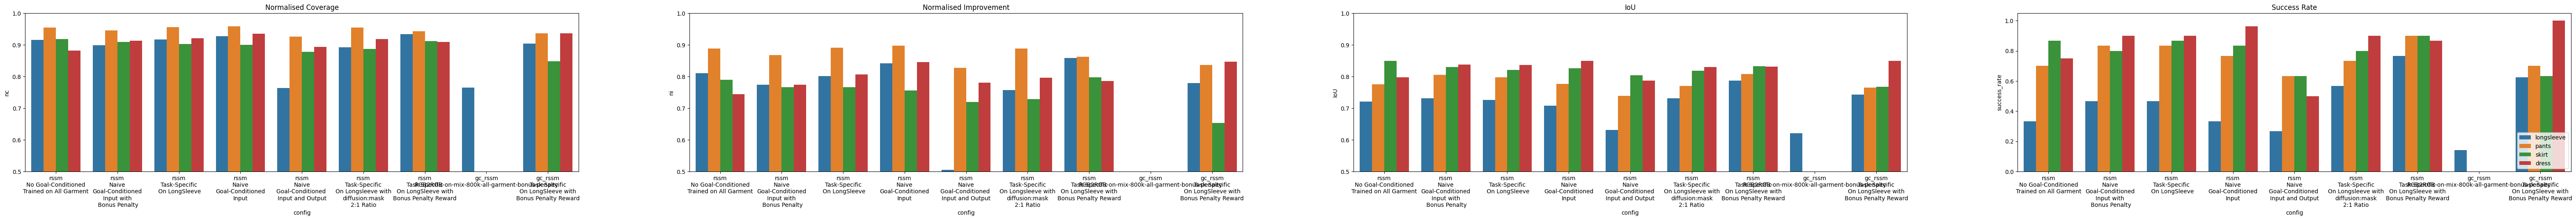

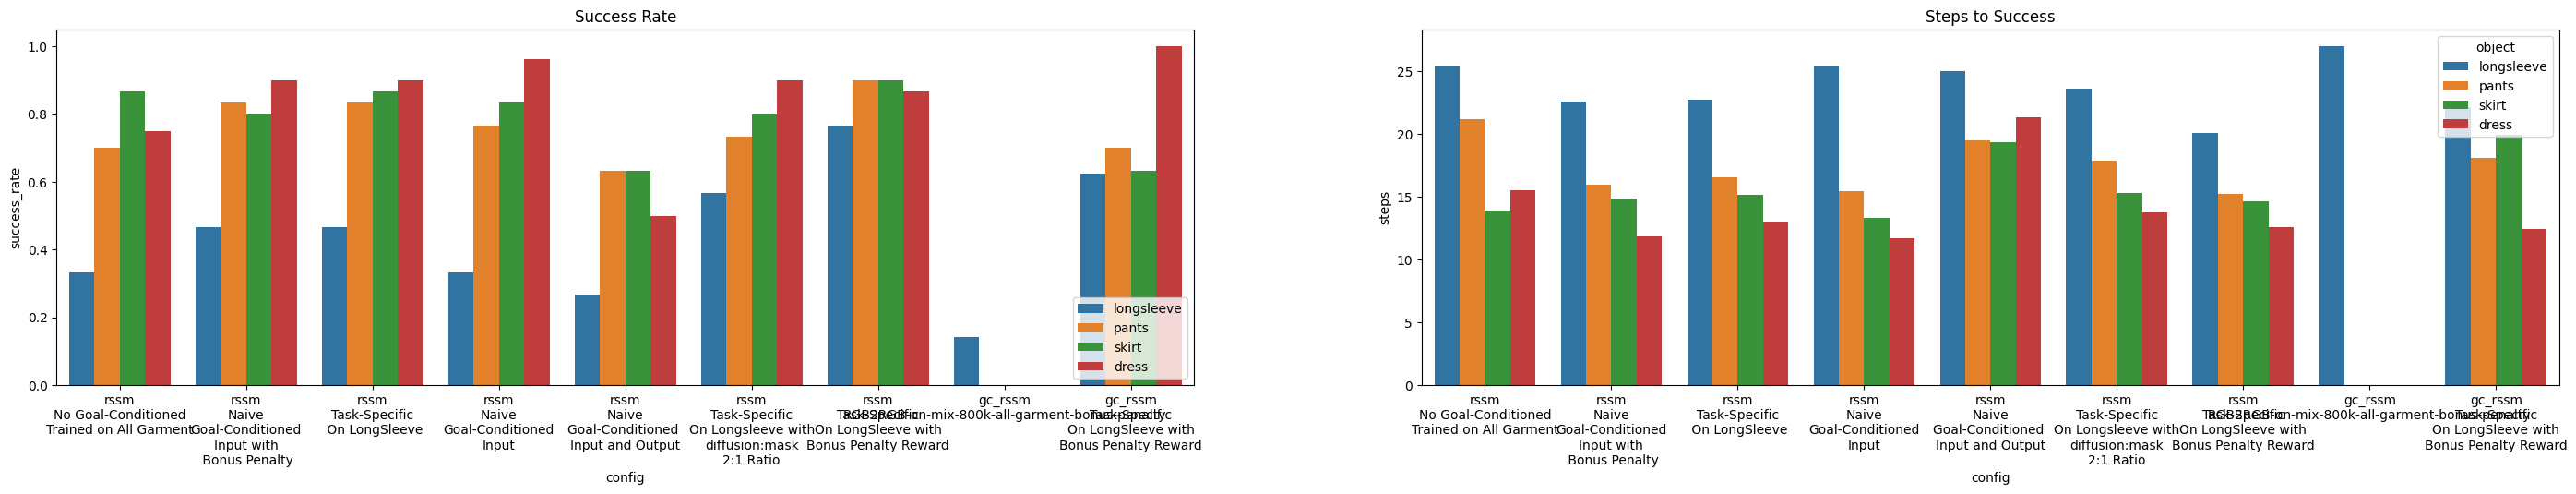

In [ ]:
## make a plot for each metrics, where the x-axis is the config and y-axis is the metrics, hue is the object; use seaborn
plot_df = df.copy()
plot_df['success_rate'] = plot_df['success_eps'] / plot_df['episodes']

config2label = {
    'RGB2RGB-on-all-garment-800k': 'No Goal-Conditioned\nTrained on All Garment',
    'GC-In-Only-RGB2RGB-on-all-garment-800k': 'Naive\nGoal-Conditioned\nInput',
    'GC-RGB2RGB-on-all-garment-800k': 'Naive\nGoal-Conditioned \nInput and Output',
    'GC-In-Only-RGB2RGB-on-all-garment-800k-bonus-penalty': 'Naive\nGoal-Conditioned\nInput with\n Bonus Penalty',
    'RGB2RGB-on-mix-800k-all-garment-bonus-penalty': 'All Garment with\nBonus Penalty Reward\n No Goal Augmentation',
    'RGB2RGB-on-mix-200k-sf': 'Task-Specific\n On LongSleeve',
    'RGB2RGB-on-mix-200k-bonus-penalty-ca': 'Task-Specific\nOn LongSleeve with\nBonus Penalty Reward',
    'RGB2RGB-on-2ratio1-mix-300k': 'Task-Specific\nOn Longsleeve with\ndiffusion:mask\n2:1 Ratio',
    
}
for k, v in config2label.items():
    plot_df['config'] = plot_df['config'].replace(k, v)

# config_order = [v for v in config2label.values()]
# plot_df['config'] = pd.Categorical(plot_df['config'], categories=config_order, ordered=True)


plot_df['config'] = plot_df['agent'] + '\n' + plot_df['config']
display(plot_df)

# sor with the config order


# put the above graphs in one line
fig, axs = plt.subplots(1, 4, figsize=(80, 5))
sns.barplot(data=plot_df, x='config', y='nc', hue='object', ax=axs[0])
axs[0].set_title('Normalised Coverage')
# set ylim to 0.5 t0 1.0
axs[0].set_ylim(0.5, 1.0)
axs[0].legend_.remove()
# turn off the legen
# s
sns.barplot(data=plot_df, x='config', y='ni', hue='object', ax=axs[1])
axs[1].set_title('Normalised Improvement')
axs[1].set_ylim(0.5, 1.0)
axs[1].legend_.remove()
# axs[1].legend(loc='lower right')
sns.barplot(data=plot_df, x='config', y='IoU', hue='object', ax=axs[2])
axs[2].set_title('IoU')
axs[2].set_ylim(0.5, 1.0)
axs[2].legend_.remove()
# axs[2].legend(loc='lower right')
sns.barplot(data=plot_df, x='config', y='success_rate', hue='object', ax=axs[3])
axs[3].set_title('Success Rate')
axs[3].legend(loc='lower right')
plt.savefig(os.path.join(analysis_pth, 'all_metrics.png'))


## plot only the success rate and steps to success
fig, axs = plt.subplots(1, 2, figsize=(35, 5))
sns.barplot(data=plot_df, x='config', y='success_rate', hue='object', ax=axs[0])
axs[0].set_title('Success Rate')
axs[0].legend_.remove()
sns.barplot(data=plot_df, x='config', y='steps', hue='object', ax=axs[1])
axs[1].set_title('Steps to Success')
axs[0].legend(loc='lower right')
# axs[1].legend_.remove()
plt.savefig(os.path.join(analysis_pth, 'success_rate_and_steps.png'))


